In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lifelines import KaplanMeierFitter
from matplotlib.gridspec import GridSpec

In [2]:
# ---
# Load data
# ---

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Dataset",
)

In [3]:
# ---
# Filter data
# ---

# Remove assets with non-positive lifespans.
df = df[
    df["Lifespan"] > 0
]

# Retain operational assets only.
df = df[
    df["Event"].isin([0])
]


In [4]:
# ---
# Configuration
# ---

technology_col = "Technology"
capacity_col = "Capacity (MW)"
start_year_col = "Start Year"
retirement_col = "Retired Year"

analysis_year = 2025


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}


In [5]:
# ---
# Style
# ---

# Minimum font size: 12 pt

FONT_MIN = 12.0
FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_TITLE = 12.5
FONT_PANEL = 12.5
FONT_GROUP_HEADER = 13.0
FONT_REFERENCE_LABEL = 12.0
FONT_INFO = 12.0
FONT_AXIS_LABEL = 13.5

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": FONT_MIN,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Palette
# ---

CURVE_COLOUR = "#222222"
REFERENCE_COLOUR = "#3F708F"
GRID_COLOUR = "#BFBFBF"
SECONDARY_TEXT_COLOUR = "#555555"
TEXT_COLOUR = "#222222"
AXIS_COLOUR = "#444444"
GROUP_LINE_COLOUR = "#777777"


In [6]:
# ---
# Prepare active fleet
# ---

df_plot = df.copy()

df_plot[start_year_col] = pd.to_numeric(
    df_plot[start_year_col],
    errors="coerce",
)

df_plot[retirement_col] = pd.to_numeric(
    df_plot[retirement_col],
    errors="coerce",
)

df_plot[capacity_col] = pd.to_numeric(
    df_plot[capacity_col],
    errors="coerce",
)

# Keep plants with no retirement year or retirement after analysis year.
df_active = df_plot[
    df_plot[start_year_col].notna()
    & df_plot[capacity_col].notna()
    & (df_plot[capacity_col] > 0)
].copy()

# Calculate asset age at the analysis year.
df_active["Age"] = (
    analysis_year
    - df_active[start_year_col]
)

df_active = df_active[
    df_active["Age"].notna()
    & (df_active["Age"] >= 0)
].copy()


In [7]:
# ---
# Helper functions
# ---

# Calculate the asset-count age-survival curve.
# S(x) is the share of active assets with age >= x.
def asset_count_survival_from_ages(
    ages,
):
    ages = np.asarray(
        ages,
        dtype=float,
    )

    valid = np.isfinite(ages)
    ages = ages[valid]

    if len(ages) == 0:
        return (
            np.array([]),
            np.array([]),
        )

    total_assets = len(ages)

    unique_ages = np.sort(
        np.unique(ages)
    )

    survival = np.array(
        [
            np.sum(ages >= age)
            / total_assets
            for age in unique_ages
        ]
    )

    # Begin at age zero with all assets.
    times = np.insert(
        unique_ages,
        0,
        0,
    )

    survival = np.insert(
        survival,
        0,
        1.0,
    )

    return times, survival


# Return the first age at which asset share reaches a given level.
def get_crossing_age(
    times,
    survival,
    level,
):
    crossed = np.where(
        survival <= level
    )[0]

    if len(crossed) == 0:
        return np.nan

    return times[crossed[0]]


# Summarise the age-survival information for one technology.
def summarise_technology(subset):
    if subset.empty:
        return None

    ages = subset["Age"].to_numpy()

    times, survival = asset_count_survival_from_ages(
        ages,
    )

    if len(times) == 0:
        return None

    return {
        "subset": subset,
        "times": times,
        "S": survival,
        "t80": get_crossing_age(
            times,
            survival,
            0.8,
        ),
        "t50": get_crossing_age(
            times,
            survival,
            0.5,
        ),
        "t10": get_crossing_age(
            times,
            survival,
            0.1,
        ),
        "max_age": np.nanmax(ages),
        "n_units": len(subset),
        "total_cap_mw": subset[capacity_col].sum(),
        "total_cap_gw": (
            subset[capacity_col].sum()
            / 1000
        ),
    }


# Order technologies from older to younger using the 50% crossing age.
def order_technologies_by_oldest(
    group_techs,
    tech_info,
):
    available = [
        tech
        for tech in group_techs
        if (
            tech in tech_info
            and tech_info[tech] is not None
        )
    ]

    return sorted(
        available,
        key=lambda tech: (
            (
                tech_info[tech]["t50"]
                if np.isfinite(
                    tech_info[tech]["t50"]
                )
                else tech_info[tech]["max_age"]
            ),
            tech_info[tech]["max_age"],
        ),
        reverse=True,
    )


# Add a group heading and separator line.
def add_group_header(
    ax,
    title,
):
    ax.axis("off")

    ax.text(
        0.0,
        0.65,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP_HEADER,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.plot(
        [0.0, 1.0],
        [0.15, 0.15],
        transform=ax.transAxes,
        color=GROUP_LINE_COLOUR,
        linewidth=0.75,
        clip_on=False,
    )


# Plot one technology panel.
def plot_panel(
    ax,
    tech,
    info,
    panel_label,
):
    subset = info["subset"]
    times = info["times"]
    survival = info["S"]

    # Active-asset age curve.
    ax.step(
        times,
        survival,
        where="post",
        color=CURVE_COLOUR,
        linewidth=1.45,
        zorder=4,
    )

    # Add 80%, 50%, and 10% reference levels.
    total_active_assets = info["n_units"]

    for level in [
        0.8,
        0.5,
        0.1,
    ]:
        crossed = np.where(
            survival <= level
        )[0]

        if len(crossed) == 0:
            continue

        idx = crossed[0]
        t_level = times[idx]

        # Cumulative capacity of active assets at or above
        # the threshold age. The survival curve itself remains
        # based on the number of assets
        cap_older_gw = (
            subset.loc[
                subset["Age"] >= t_level,
                capacity_col,
            ].sum()
            / 1000
        )

        # Give the median reference stronger emphasis.
        is_median = level == 0.5
        line_alpha = 0.95 if is_median else 0.60
        line_width = 1.00 if is_median else 0.80
        text_alpha = 1.00 if is_median else 0.80

        ax.hlines(
            y=level,
            xmin=0,
            xmax=t_level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.vlines(
            x=t_level,
            ymin=0,
            ymax=level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.text(
            t_level + 1.5,
            min(
                level + 0.018,
                0.98,
            ),
            (
                f"{t_level:.0f} y\n"
                f"{cap_older_gw:.1f} GW"
            ),
            ha="left",
            va="bottom",
            fontsize=FONT_REFERENCE_LABEL,
            fontweight=(
                "bold"
                if is_median
                else "normal"
            ),
            color=REFERENCE_COLOUR,
            alpha=text_alpha,
            linespacing=1.05,
            zorder=5,
        )

    # Technology-level sample information.
    ax.text(
        0.97,
        0.95,
        (
            f'n = {info["n_units"]:,} | '
            f'{info["total_cap_gw"]:.2f} GW'
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=FONT_INFO,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
    )

    # Panel label and technology title.
    ax.text(
        -0.13,
        1.12,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )

    # Axes.
    ax.set_xlim(
        0,
        125,
    )

    ax.set_ylim(
        0,
        1.02,
    )

    ax.set_xticks(
        np.arange(
            0,
            126,
            25,
        )
    )

    ax.set_yticks(
        [
            0,
            0.1,
            0.5,
            0.8,
            1.0,
        ]
    )

    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    for spine in [
        "top",
        "right",
    ]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.spines["left"].set_color(AXIS_COLOUR)
    ax.spines["bottom"].set_color(AXIS_COLOUR)

    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelbottom=True,
        labelleft=True,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )


In [8]:
# ---
# Pre-calculate technology information
# ---

tech_info = {}

all_group_techs = [
    tech
    for group in tech_groups.values()
    for tech in group
]

for tech in all_group_techs:
    subset = df_active[
        df_active[technology_col] == tech
    ].copy()

    tech_info[tech] = summarise_technology(
        subset
    )


# ---
# Order technologies
# ---

ordered_groups = {
    group_name: order_technologies_by_oldest(
        group_techs,
        tech_info,
    )
    for group_name, group_techs in tech_groups.items()
}



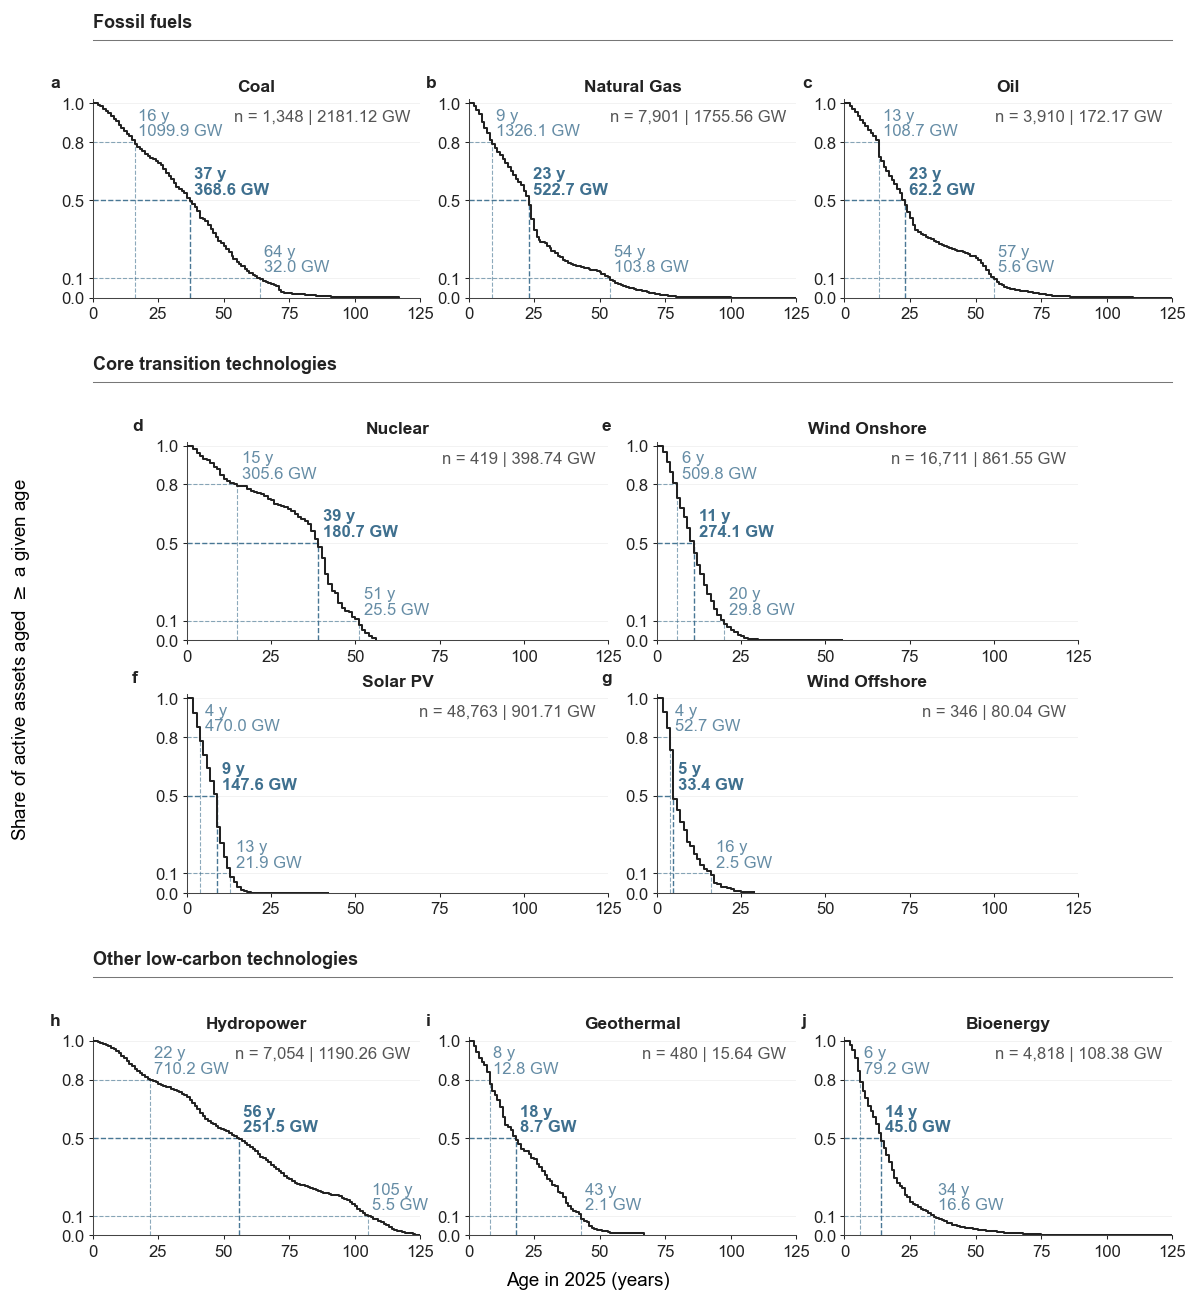

In [9]:
# ---
# Figure
# ---

group_names = list(
    ordered_groups.keys()
)

# Fossil fuels: 1 x 3
# Core transition technologies: 2 x 2
# Other low-carbon technologies: 1 x 3
group_layout = {
    "Fossil fuels": {
        "header_row": 0,
        "panel_rows": [1],
    },
    "Core transition technologies": {
        "header_row": 2,
        "panel_rows": [3, 4],
    },
    "Other low-carbon technologies": {
        "header_row": 5,
        "panel_rows": [6],
    },
}

fig = plt.figure(
    figsize=(
        11.8,
        13.4,
    )
)

gs = GridSpec(
    nrows=7,
    ncols=12,
    figure=fig,
    height_ratios=[
        0.18,
        1.0,
        0.18,
        1.0,
        1.0,
        0.18,
        1.0,
    ],
    hspace=0.42,
    wspace=1.05,
)


# ---
# Group headers
# ---

for group_name in group_names:
    layout = group_layout[
        group_name
    ]

    ax_header = fig.add_subplot(
        gs[
            layout["header_row"],
            :,
        ]
    )

    add_group_header(
        ax_header,
        group_name,
    )


# ---
# Panel positions
# ---

def get_panel_positions(
    row_indices,
    n_panels,
):
    if n_panels == 3 and len(row_indices) == 1:
        row_index = row_indices[0]

        return [
            (row_index, slice(0, 4)),
            (row_index, slice(4, 8)),
            (row_index, slice(8, 12)),
        ]

    if n_panels == 4 and len(row_indices) == 2:
        top_row, bottom_row = row_indices

        return [
            (top_row, slice(1, 6)),
            (top_row, slice(6, 11)),
            (bottom_row, slice(1, 6)),
            (bottom_row, slice(6, 11)),
        ]

    raise ValueError(
        "Expected either three panels in one row "
        "or four panels in a 2 x 2 layout."
    )


# ---
# Create panels
# ---

share_ax = None
panel_counter = 0

for group_name in group_names:
    tech_list = ordered_groups[
        group_name
    ]

    layout = group_layout[
        group_name
    ]

    positions = get_panel_positions(
        layout["panel_rows"],
        len(tech_list),
    )

    for tech, (
        panel_row,
        col_slice,
    ) in zip(
        tech_list,
        positions,
    ):
        if share_ax is None:
            ax = fig.add_subplot(
                gs[
                    panel_row,
                    col_slice,
                ]
            )
            share_ax = ax

        else:
            ax = fig.add_subplot(
                gs[
                    panel_row,
                    col_slice,
                ],
                sharex=share_ax,
                sharey=share_ax,
            )

        plot_panel(
            ax=ax,
            tech=tech,
            info=tech_info[tech],
            panel_label=chr(
                97 + panel_counter
            ),
        )

        panel_counter += 1


# ---
# Global labels
# ---

fig.supylabel(
    r"Share of active assets aged $\geq$ a given age",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
)

fig.supxlabel(
    f"Age in {analysis_year} (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.030,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.070,
    top=0.985,
)


# ---
# Save
# ---

plt.savefig(
    "figures/si/figure-7.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/si/figure-7.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()
